# 02 – Baseline-Demo (Meilenstein 1)

Random Forest auf 131 Bändern + AEZ + Monat, Zielklasse Crop×Stage, 70/30-Split. Läuft in unter einer Minute.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image, display, Markdown
from dp2 import config as C, data as D
FIG = C.FIGURES

In [2]:
from dp2.features import FeatureBuilder, FeatureSpec
from dp2.models import factory
from dp2.strategies import Flat
from dp2.evaluation import holdout_stratified, holdout_cluster, holdout_eval
from dp2.metrics import fmt
ds = D.load(); tr = ds.train; pairs = D.valid_pairs(tr)
X = FeatureBuilder(ds.bands, ds.wl, FeatureSpec(meta='ordinal')).fit(tr).transform(tr)
crop, stage = tr.Crop.to_numpy(object), tr.Stage.to_numpy(object)
X.shape

(5589, 133)

## Pipeline
1. Leere Bänder entfernen, Einzellücken je Spektrum linear interpolieren, Duplikate entfernen
2. Merkmale: 131 Reflexionswerte + AEZ + Monat
3. Random Forest (500 Bäume, Klassengewichte)

In [3]:
a, b = holdout_stratified(tr.Combo.values)
m, c, s, model = holdout_eval(lambda: Flat(factory('rf'), pairs), X, crop, stage, a, b)
print('stratifiziert 70/30:', fmt(m))
a2, b2, _ = holdout_cluster(tr, ds.X_train)
m2, *_ = holdout_eval(lambda: Flat(factory('rf'), pairs), X, crop, stage, a2, b2)
print('Cluster 70/30:     ', fmt(m2))

stratifiziert 70/30: bacc_crop=0.8271  bacc_stage=0.8290  bacc_combo=0.6916  f1_combo=0.7182  f1_samples=0.8578


Cluster 70/30:      bacc_crop=0.6520  bacc_stage=0.5980  bacc_combo=0.3902  f1_combo=0.4005  f1_samples=0.6989


Der **Cluster-Split** hält ganze Gruppen spektral ähnlicher Pixel (≈ dasselbe Feld) zurück. Die große Lücke zeigt: Ein Teil der Leistung beim Zufallssplit ist 'Wiedererkennen' benachbarter Pixel. Für den offiziellen Test (ebenfalls Zufallsausschnitt) ist der stratifizierte Split die richtige Schätzung, für neue Felder der Cluster-Split.

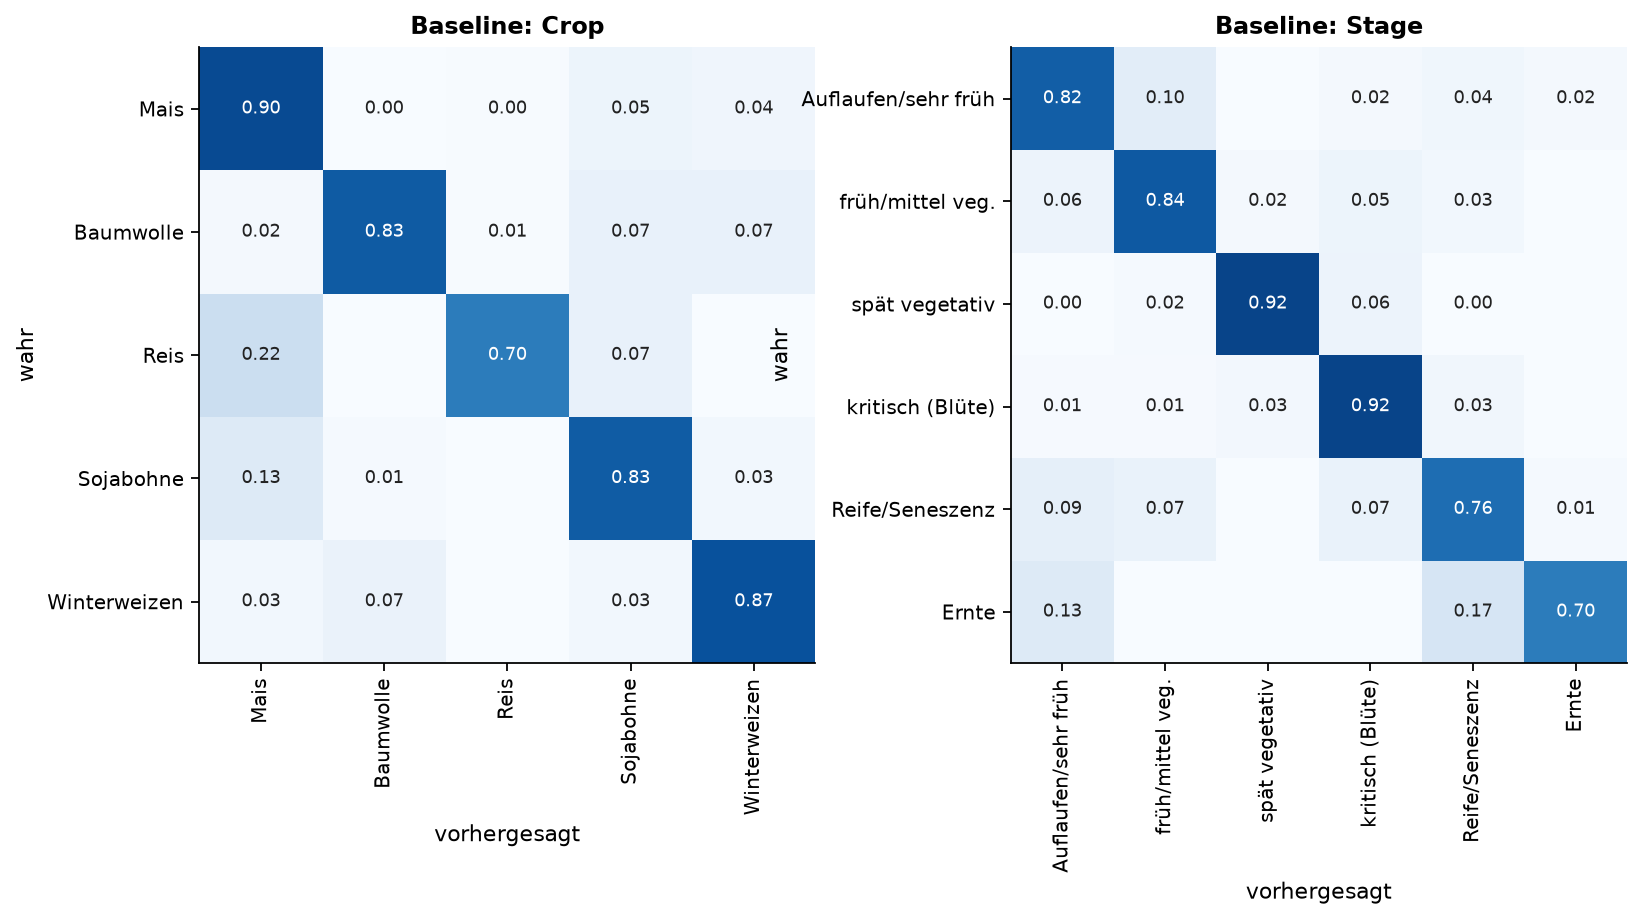

In [4]:
display(Image(FIG / 'm1_baseline_confusion.png'))